This demo is largely based on scikit-learn examples: the [`RandomForestClassifier` documentation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html) and the [OOB error example](https://scikit-learn.org/stable/auto_examples/ensemble/plot_ensemble_oob.html).

In [1]:
import warnings

import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# Random Forest

The sklearn.ensemble module includes the RandomForest averaging algorithm, based on randomized decision trees. It is a perturb-and-combine technique specifically designed for trees. This means a diverse set of classifiers is created by introducing randomness in the classifier construction. The prediction of the ensemble is given as the averaged prediction of the individual classifiers.

As other classifiers, forest classifiers have to be fitted with two arrays: a sparse or dense array X of size [n_samples, n_features] holding the training samples, and an array Y of size [n_samples] holding the target values (class labels) for the training samples.

In random forests (see RandomForestClassifier and RandomForestRegressor classes), each tree in the ensemble is built from a sample drawn with replacement (i.e., a bootstrap sample) from the training set. In addition, when splitting a node during the construction of the tree, the split that is chosen is no longer the best split among all features. Instead, the split that is picked is the best split among a random subset of the features. As a result of this randomness, the bias of the forest usually slightly increases (with respect to the bias of a single non-random tree) but, due to averaging, its variance also decreases, usually more than compensating for the increase in bias, hence yielding an overall better model.

In contrast to the original publication, the scikit-learn implementation combines classifiers by averaging their probabilistic prediction, instead of letting each classifier vote for a single class.

In the example below, we fit a forest (`fit(X, y)`) on 4 features, of which only the first 2 are informative (with `shuffle=False`, the informative features are the first columns). `feature_importances_` gives each feature's importance for the forest, and `predict` the class of a new sample.

In [2]:
from sklearn.datasets import make_classification
from sklearn.ensemble import RandomForestClassifier

X, y = make_classification(
  n_samples=1000,
  n_features=4,
  n_informative=2,
  n_redundant=0,
  random_state=0,
  shuffle=False,
)
model = RandomForestClassifier(max_depth=2, random_state=0)
model.fit(X, y)

print(model.feature_importances_)
print(model.predict([[0, 0, 0, 0]]))

[0.14205973 0.76664038 0.0282433  0.06305659]
[1]


The two informative features (the first two) get the highest importances, about 0.14 and 0.77, against about 0.03 and 0.06 for the two noise features. This is the impurity-based importance from the slides (`feature_importances_`), computed on the training set.

## OOB Errors for Random Forests

The RandomForestClassifier is trained using bootstrap aggregation, where each new tree is fit from a bootstrap sample of the training observations z_i = (x_i, y_i). The out-of-bag (OOB) error is the average error for each z_i calculated using predictions from the trees that do not contain z_i in their respective bootstrap sample. This allows the RandomForestClassifier to be fit and validated whilst being trained.

The example below demonstrates how the OOB error can be measured at the addition of each new tree during training. The resulting plot allows a practitioner to approximate a suitable value of n_estimators at which the error stabilizes.

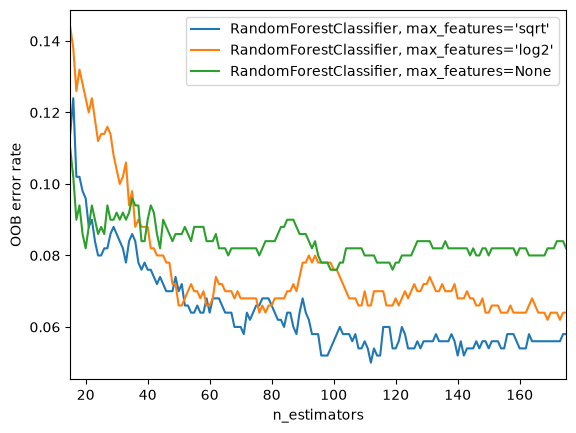

In [3]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.ensemble import RandomForestClassifier

# Author: Kian Ho <hui.kian.ho@gmail.com>
#         Gilles Louppe <g.louppe@gmail.com>
#         Andreas Mueller <amueller@ais.uni-bonn.de>
#
# License: BSD 3 Clause

RANDOM_STATE = 123

# Generate a binary classification dataset.
X, y = make_classification(
  n_samples=500,
  n_features=25,
  n_clusters_per_class=1,
  n_informative=15,
  random_state=RANDOM_STATE,
)

# NOTE: Setting the `warm_start` construction parameter to `True` disables
# support for parallelized ensembles but is necessary for tracking the OOB
# error trajectory during training.
ensemble_models = [
  (
    "RandomForestClassifier, max_features='sqrt'",
    RandomForestClassifier(
      warm_start=True,
      oob_score=True,
      max_features="sqrt",
      random_state=RANDOM_STATE,
    ),
  ),
  (
    "RandomForestClassifier, max_features='log2'",
    RandomForestClassifier(
      warm_start=True,
      max_features="log2",
      oob_score=True,
      random_state=RANDOM_STATE,
    ),
  ),
  (
    "RandomForestClassifier, max_features=None",
    RandomForestClassifier(
      warm_start=True,
      max_features=None,
      oob_score=True,
      random_state=RANDOM_STATE,
    ),
  ),
]

# Map a classifier name to a list of (<n_estimators>, <error rate>) pairs.
error_rate = {label: [] for label, _ in ensemble_models}

# Range of `n_estimators` values to explore.
min_estimators = 15
max_estimators = 175

for label, model in ensemble_models:
  for i in range(min_estimators, max_estimators + 1):
    model.set_params(n_estimators=i)
    model.fit(X, y)

    # Record the OOB error for each `n_estimators=i` setting.
    oob_error = 1 - model.oob_score_
    error_rate[label].append((i, oob_error))

# Generate the "OOB error rate" vs. "n_estimators" plot.
for label, model_err in error_rate.items():
  xs, ys = zip(*model_err)
  plt.plot(xs, ys, label=label)

plt.xlim(min_estimators, max_estimators)
plt.xlabel("n_estimators")
plt.ylabel("OOB error rate")
plt.legend(loc="upper right")
plt.show()

The OOB error goes down as trees are added, then levels off after about a hundred trees. The `sqrt` and `log2` curves end lower (between 5% and 7%) than `max_features=None` (around 8%): without column sampling, all the trees pick their splits among the same features, look alike and correct each other less. This is the idea of "Tool 2 — Column sampling" in the slides.

## Displaying a tree of the forest

The trees of the forests in the previous loop are too deep to be read. To see what a forest tree looks like, we fit a small forest, with depth limited to 3, and display its first tree with `plot_tree`.

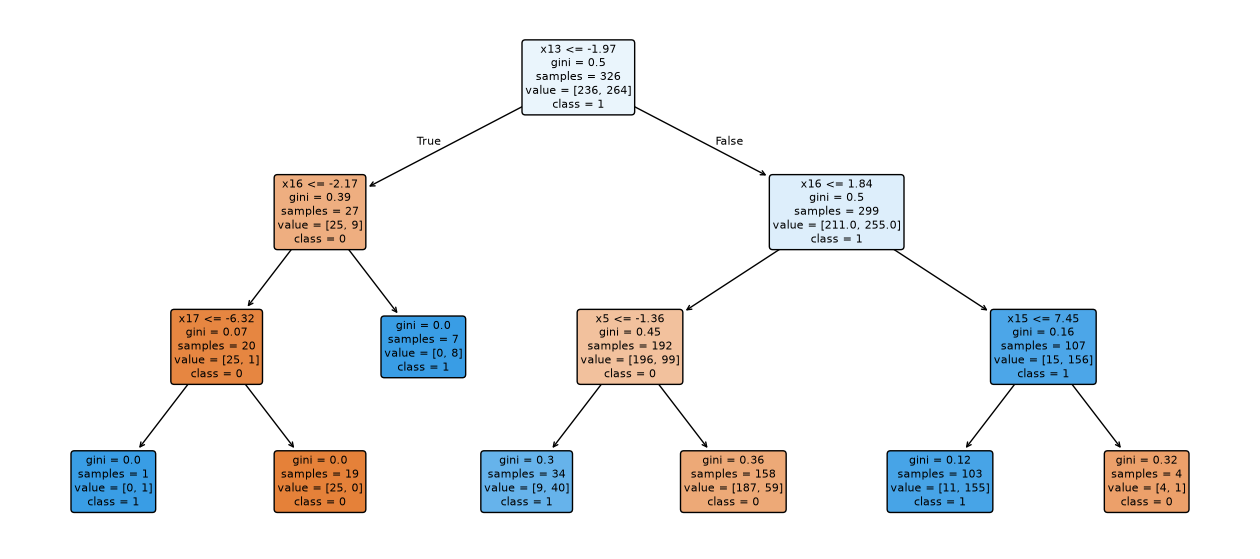

In [4]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import plot_tree

# A small forest, with depth-3 trees, for a readable tree
small_forest = RandomForestClassifier(
  n_estimators=10, max_depth=3, random_state=RANDOM_STATE
).fit(X, y)

plt.figure(figsize=(16, 7))
plot_tree(
  small_forest.estimators_[0],
  feature_names=[f"x{i}" for i in range(X.shape[1])],
  class_names=["0", "1"],
  filled=True,
  rounded=True,
  precision=2,
  fontsize=8,
)
plt.show()